# MVP — Análise de Dados e Boas Práticas

**Título do projeto:** A bilheteria do cinema no Brasil (2009–2017): evolução do mercado, concentração e o espaço do cinema nacional

**Nome:** Daniel Siqueira

**Matrícula:** 40530010055

**Dataset:** Bilheteria de Obras por Semana — ANCINE (Dados Abertos do Governo Federal)

**Versão entregue:** v1.0 — novembro/2026 *(atualizar na data de entrega)*

**Google Colab:** [abrir notebook](https://colab.research.google.com/github/danielsiqueiradev/MVP_Analise_De_Dados_PUC-RJ/blob/main/MVP_Bilheteria_Cinema_Brasileiro.ipynb)

# 1. Problema e perguntas

## 1.1 Contexto e objetivo

O Brasil figura entre os maiores mercados de cinema do mundo em número de espectadores, mas convive com um paradoxo recorrente no debate público e na política audiovisual: a maior parte da renda de bilheteria vem de filmes estrangeiros — sobretudo de Hollywood — enquanto a produção nacional disputa uma fatia pequena e instável do público. Medidas de fomento (cotas de tela, fundos setoriais, renúncia fiscal) são avaliadas continuamente, e qualquer discussão sobre o "espaço do cinema nacional" passa por quantificar o que de fato aconteceu nas bilheterias.

**Problema:** caracterizar o mercado de bilheteria de cinema no Brasil entre 2009 e 2017 — sua evolução, concentração, sazonalidade e a participação efetiva das obras nacionais — a partir dos registros oficiais de exibição da ANCINE.

**Unidade de observação:** cada linha do dataset representa **uma obra cinematográfica (filme) em uma semana de exibição** no circuito comercial brasileiro — público, renda, salas e cópias daquela obra naquela semana. A semana de exibição do mercado brasileiro vai de quinta a quarta-feira.

**Objetivo analítico:** descritivo-diagnóstico — produzir uma caracterização empírica do mercado e deixar os dados limpos, documentados e estruturados em dois níveis (obra × semana e obra agregada). Caso a base seja usada futuramente em etapa preditiva, o problema natural seria uma **regressão** com alvo `PUBLICO` (público total ou da primeira semana de exibição), com atributos como gênero, origem, distribuidora, salas de estreia e mês — por exemplo, estimar o potencial de público de um lançamento. Essa etapa **não** faz parte do escopo deste trabalho, que termina na preparação dos dados.

## 1.2 Perguntas ou hipóteses

- **H1:** A renda de bilheteria cresceu proporcionalmente mais que o público entre 2009 e 2017, puxada pelo reajuste do preço médio do ingresso.
- **H2:** Obras nacionais representam parcela relevante do catálogo exibido, mas capturam fatia menor e instável do público, dependente de poucos grandes sucessos por ano.
- **H3:** O mercado é concentrado — poucas obras e poucas distribuidoras respondem pela maior parte do público (padrão tipo Pareto).
- **H4:** Ficção e obras dos EUA dominam a bilheteria; documentário tem presença de catálogo sem presença correspondente de público.
- **H5:** Existe sazonalidade mensal na frequência aos cinemas, com picos nos meses de férias escolares.
- **H6:** A permanência típica em cartaz é curta e o público cresce com o número de salas, porém com rendimento decrescente por sala (saturação).

**Premissas e restrições:** a análise assume que os dados reportados à ANCINE cobrem razoavelmente o circuito comercial registrado. O que os dados **não** permitem concluir: qualquer inferência causal (ex.: "mais salas causam mais público" — a capilaridade é também resposta à demanda esperada); evolução da renda em termos reais, pois `RENDA` é nominal; comportamento dentro da semana ou por tipo de sessão (3D, meia-entrada, sala premium), pois o ticket médio é uma razão agregada; e qualquer leitura do período posterior a 2017 (streaming, pandemia, recuperação).

# 2. Fonte e significado dos dados

## 2.1 Proveniência e acesso

- **Fonte original:** ANCINE — Agência Nacional do Cinema, Dados Abertos do Governo Federal / Observatório Brasileiro do Cinema e do Audiovisual (OCA): https://dados.gov.br · https://oca.ancine.gov.br
- **Arquivo:** `BilheteriaObrasSemana.csv`
- **Data de obtenção:** novembro de 2026
- **Período coberto:** anos cinematográficos de 2009 a 2017 (semanas de exibição entre 02/01/2009 e 03/01/2018)
- **Condições de uso:** dados públicos abertos, sem informações pessoais, sigilosas ou credenciais
- **Recortes/filtros aplicados:** nenhum — o arquivo é utilizado integralmente
- **Como obter exatamente estes dados:** o CSV é versionado neste repositório (`data/BilheteriaObrasSemana.csv`) e o notebook o lê pela URL pública *raw* do GitHub (seção 3), sem necessidade de conta ou credencial

## 2.2 Dicionário das variáveis

| Variável | Significado | Tipo | Unidade ou categorias | Observações e valores de ausência |
|---|---|---|---|---|
| `TITULO_ORIGINAL` | Título original da obra | texto | — | Não é chave confiável (títulos se repetem entre obras) |
| `TITULO_BRASILEIRO` | Título de lançamento no Brasil | texto | — | 10 títulos compartilhados por obras distintas |
| `GENERO` | Categoria da obra | categórica | Ficção, Documentário, Animação, Vídeomusical, Não Classificada | — |
| `PAIS_ORIGEM` | País(es) de origem | texto | lista separada por vírgula | Espaços à esquerda; coproduções têm ≥2 países |
| `CPB_ROE` | **Identificador único da obra** (Registro de Obras ANCINE) | código | prefixo `B`/`E` | `B` = registrada brasileira, `E` = estrangeira; chave de agregação, não medida |
| `COPIAS` | Cópias disponibilizadas | inteira | cópias | **Não confiável no recorte semanal** (0 em 38% dos registros com salas ≥1) — ver D2 |
| `SALAS` | Salas exibindo a obra na semana | inteira | salas | Medida de capilaridade adotada |
| `DT_INICIO_EXIBICAO` | Início da semana de exibição | data | AAAA-MM-DD | — |
| `DT_FIM_EXIBICAO` | Fim da semana de exibição | data | AAAA-MM-DD | Semanas típicas de 6 dias; 118 de 5 dias (fechamento do ano cinematográfico, março) |
| `PUBLICO` | Ingressos vendidos na semana | inteira | espectadores | 54 registros com 0 (sem movimento reportado) — ver D3 |
| `RENDA` | Renda bruta de bilheteria na semana | decimal | R$ **nominal** | Sem correção de inflação |
| `RAZAO_SOCIAL_DISTRIBUIDORA` | Nome da distribuidora | texto | 274 variações | Variações cadastrais de um mesmo CNPJ |
| `REGISTRO_DISTRIBUIDORA` | Registro ANCINE da distribuidora | código | — | Identificador, não medida |
| `CNPJ_DISTRIBUIDORA` | CNPJ da distribuidora | código | 268 distintos | Identificador estável usado para agregar distribuidoras |
| `ANO_CINEMATOGRAFICO` | Ano cinematográfico oficial ANCINE | data | ano | ≠ ano civil: semanas na virada do ano pertencem ao ano cinematográfico oficial |

**Variáveis derivadas neste trabalho** (seção 5): `ANO` (inteiro), `MES` (1–12), `PAIS_PRINCIPAL` (1º país da lista), `N_PAISES`, `COPRODUCAO` (bool), `NACIONAL`/`ORIGEM` (ver D1), `TICKET_MEDIO` (`RENDA`/`PUBLICO`, R$; `NaN` estrutural onde `PUBLICO = 0`), `SEMANAS_CARTAZ` e `SALAS_MAX` (nível obra).

# 3. Ambiente e carregamento

In [1]:
import sys
from importlib.metadata import version

print("Python:", sys.version.split()[0])
for pacote in ("pandas", "numpy", "matplotlib", "seaborn"):
    print(f"{pacote}: {version(pacote)}")

Python: 3.11.9
pandas: 3.0.3
numpy: 2.4.6
matplotlib: 3.10.9
seaborn: 0.13.2


In [2]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.titlesize"] = 13
pd.set_option("display.max_columns", 30)

SEED = 42
np.random.seed(SEED)  # nenhuma operacao aleatoria neste trabalho; seed por convencao

COR_NAC, COR_ESTR = "#2ca02c", "#1f77b4"  # verde = nacional, azul = estrangeira

# Carga: URL publica raw do GitHub (mecanismo oficial de reproducao).
# O fallback para data/ existe apenas para desenvolvimento offline.
DATA_URL = ("https://raw.githubusercontent.com/danielsiqueiradev/"
            "MVP_Analise_De_Dados_PUC-RJ/main/data/BilheteriaObrasSemana.csv")
try:
    df_raw = pd.read_csv(DATA_URL)
    origem_dados = f"repositorio GitHub (raw): {DATA_URL}"
except Exception:
    df_raw = pd.read_csv("data/BilheteriaObrasSemana.csv")
    origem_dados = "copia local em data/ (fallback para execucao offline)"

# df_raw permanece intocado como visao original para comparacoes antes/depois;
# df e df_obras (secao 5) sao as versoes transformadas.
print(f"Origem: {origem_dados}")
print(f"{df_raw.shape[0]:,} registros x {df_raw.shape[1]} colunas")
df_raw.head()

Origem: repositorio GitHub (raw): https://raw.githubusercontent.com/danielsiqueiradev/MVP_Analise_De_Dados_PUC-RJ/main/data/BilheteriaObrasSemana.csv
51,176 registros x 15 colunas


,TITULO_ORIGINAL,TITULO_BRASILEIRO,GENERO,PAIS_ORIGEM,CPB_ROE,COPIAS,SALAS,DT_INICIO_EXIBICAO,DT_FIM_EXIBICAO,PUBLICO,RENDA,RAZAO_SOCIAL_DISTRIBUIDORA,REGISTRO_DISTRIBUIDORA,CNPJ_DISTRIBUIDORA,ANO_CINEMATOGRAFICO
0,COLLEGE,COLEGIAIS EM APUROS,Ficção,Estados Unidos,E1600557700000,8,8,2009-01-02,2009-01-08,833,5325.00,ANTONIO FERNANDES FILMES LTDA,532,02.668.665/0001-01,2009-01-01
1,O ABORTO DOS OUTROS,O ABORTO DOS OUTROS,Documentário,Brasil,B0800890900000,1,1,2009-01-02,2009-01-08,40,196.00,ANTONIO FERNANDES FILMES LTDA,532,02.668.665/0001-01,2009-01-01
2,ONDE ANDARÁ DULCE VEIGA?,ONDE ANDARÁ DULCE VEIGA?,Ficção,"Brasil, Chile",B0700801600000,1,1,2009-01-02,2009-01-08,66,210.00,ANTONIO FERNANDES FILMES LTDA,532,02.668.665/0001-01,2009-01-01
3,QUAND J'ETAIS CHANTEUR,QUANDO ESTOU AMANDO,Ficção,França,E1600545500000,1,1,2009-01-02,2009-01-08,103,842.92,ANTONIO FERNANDES FILMES LTDA,532,02.668.665/0001-01,2009-01-01
4,REC,REC,Ficção,Espanha,E1600619700000,2,2,2009-01-02,2009-01-08,252,1575.00,ANTONIO FERNANDES FILMES LTDA,532,02.668.665/0001-01,2009-01-01


# 4. Análise exploratória

## 4.1 Dimensões, tipos e qualidade

In [3]:
df_raw.info()
print()
print("Ausencias por coluna:", df_raw.isna().sum().sum(), "(total)")
print("Registros duplicados (linha inteira):", df_raw.duplicated().sum())
print("Duplicidade funcional (mesma obra + mesma semana):",
      df_raw.duplicated(subset=["CPB_ROE", "DT_INICIO_EXIBICAO"]).sum())

<class 'pandas.DataFrame'>
RangeIndex: 51176 entries, 0 to 51175
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   TITULO_ORIGINAL             51176 non-null  str    
 1   TITULO_BRASILEIRO           51176 non-null  str    
 2   GENERO                      51176 non-null  str    
 3   PAIS_ORIGEM                 51176 non-null  str    
 4   CPB_ROE                     51176 non-null  str    
 5   COPIAS                      51176 non-null  int64  
 6   SALAS                       51176 non-null  int64  
 7   DT_INICIO_EXIBICAO          51176 non-null  str    
 8   DT_FIM_EXIBICAO             51176 non-null  str    
 9   PUBLICO                     51176 non-null  int64  
 10  RENDA                       51176 non-null  float64
 11  RAZAO_SOCIAL_DISTRIBUIDORA  51176 non-null  str    
 12  REGISTRO_DISTRIBUIDORA      51176 non-null  int64  
 13  CNPJ_DISTRIBUIDORA          51176 non-null

Registros duplicados (linha inteira): 0
Duplicidade funcional (mesma obra + mesma semana): 65


In [4]:
# Consistencia temporal
_dt_ini = pd.to_datetime(df_raw["DT_INICIO_EXIBICAO"])
_dt_fim = pd.to_datetime(df_raw["DT_FIM_EXIBICAO"])
dur = (_dt_fim - _dt_ini).dt.days

print(f"Periodo coberto: {_dt_ini.min().date()} a {_dt_fim.max().date()}")
print(f"Duracao das semanas (dias): {dur.value_counts().to_dict()}")
print("Meses de inicio das semanas 'curtas':", sorted(_dt_ini[dur < 6].dt.month.unique()))
ano_cine = pd.to_datetime(df_raw["ANO_CINEMATOGRAFICO"]).dt.year
print(f"Registros com ano civil != ano cinematografico: {(_dt_ini.dt.year != ano_cine).sum()}")

# Zeros e inconsistencias de preenchimento
print(f"\nPUBLICO = 0: {(df_raw['PUBLICO'] == 0).sum()} | RENDA = 0: {(df_raw['RENDA'] == 0).sum()}")
print(f"PUBLICO = 0 e RENDA = 0 simultaneos: {((df_raw['PUBLICO'] == 0) & (df_raw['RENDA'] == 0)).sum()}")
print(f"COPIAS = 0 com SALAS >= 1: {((df_raw['COPIAS'] == 0) & (df_raw['SALAS'] >= 1)).sum()} "
      f"({((df_raw['COPIAS'] == 0) & (df_raw['SALAS'] >= 1)).mean():.0%})")
print(f"SALAS > COPIAS: {(df_raw['SALAS'] > df_raw['COPIAS']).sum()}")

# Divergencia cadastral: prefixo do CPB_ROE vs pais de origem
print("\nPrefixo CPB_ROE x 'Brasil' em PAIS_ORIGEM:")
print(pd.crosstab(df_raw["CPB_ROE"].str[0],
                  df_raw["PAIS_ORIGEM"].str.contains("Brasil"),
                  rownames=["CPB"], colnames=["contem Brasil"]))

Periodo coberto: 2009-01-02 a 2018-01-03


Duracao das semanas (dias): {6: 51058, 5: 118}
Meses de inicio das semanas 'curtas': [np.int32(3)]
Registros com ano civil != ano cinematografico: 90

PUBLICO = 0: 54 | RENDA = 0: 80
PUBLICO = 0 e RENDA = 0 simultaneos: 54
COPIAS = 0 com SALAS >= 1: 19473 (38%)
SALAS > COPIAS: 25458

Prefixo CPB_ROE x 'Brasil' em PAIS_ORIGEM:
contem Brasil  False  True 
CPB                        
B                  0  12813
E              38221    142


In [5]:
# Valores extremos: erro de registro ou fato do fenomeno?
print("Top 5 maiores publicos semanais:")
top_pub = df_raw.nlargest(5, "PUBLICO")[["TITULO_BRASILEIRO", "DT_INICIO_EXIBICAO",
                                        "SALAS", "PUBLICO", "RENDA"]]
print(top_pub.to_string(index=False))
tk = df_raw["RENDA"] / df_raw["PUBLICO"].replace(0, np.nan)
print("\nTicket medio implicito (RENDA/PUBLICO) dos 5 maiores:",
      (top_pub["RENDA"] / top_pub["PUBLICO"]).round(2).tolist())
print(f"Tickets implicitos fora de R$1-100: {(tk < 1).sum() + (tk > 100).sum()} "
      f"de {tk.notna().sum():,} registros com publico > 0")

Top 5 maiores publicos semanais:
                     TITULO_BRASILEIRO DT_INICIO_EXIBICAO  SALAS  PUBLICO       RENDA
         CAPITÃO AMÉRICA: GUERRA CIVIL         2016-04-28   1635  4074628 61046213.00
A SAGA CREPÚSCULO: AMANHECER - PARTE 2         2012-11-16   1194  3624972 38738922.12
           THE AVENGERS: OS VINGADORES         2012-04-27   1042  3540885 42865248.00
                  VELOZES & FURIOSOS 7         2015-04-02   1046  3538924 51861669.22
             VINGADORES: ERA DE ULTRON         2015-04-23   1356  3504303 50493946.00

Ticket medio implicito (RENDA/PUBLICO) dos 5 maiores: [14.98, 10.69, 12.11, 14.65, 14.41]
Tickets implicitos fora de R$1-100: 74 de 51,122 registros com publico > 0


**Diagnóstico:** 51.176 registros × 15 colunas, **sem ausências e sem duplicidades** (nem de linha inteira nem de obra × semana). Cobertura de 02/01/2009 a 03/01/2018, organizada em semanas de exibição de 6 dias — as 118 semanas "curtas" de 5 dias são todas de março, fechamento do ano cinematográfico ANCINE, característica do calendário oficial e não erro.

**Extremos × erros de registro:** os valores máximos de `PUBLICO` são fatos do fenômeno — estreia de *Capitão América: Guerra Civil* com 4,07 milhões de espectadores em 1.635 salas e ticket implícito de R$ 14,98 —, não erros; tickets implícitos fora de R$ 1–100 somam só 74 registros (sessões-evento/promoções). Já as **inconsistências cadastrais** exigem decisão de preparação: `COPIAS = 0` em 38% dos registros com salas ≥ 1 (D2); 54 registros com `PUBLICO = RENDA = 0` (D3); e 142 registros com prefixo `E` (estrangeira) no `CPB_ROE` mas "Brasil" no país de origem (D1).

## 4.2 Estatísticas descritivas

Aplicam-se mínimo, máximo, mediana, moda, média, desvio-padrão e ausências às medidas `COPIAS`, `SALAS`, `PUBLICO` e `RENDA`. Para os **identificadores** (`CPB_ROE`, `CNPJ_DISTRIBUIDORA`, `REGISTRO_DISTRIBUIDORA`) e **datas**, essas medidas não têm significado estatístico — em vez disso, contam-se valores distintos; para as categóricas, examinam-se frequências.

In [6]:
def estatisticas_numericas(frame, colunas):
    '''Min, max, mediana, moda, media, desvio-padrao e ausencias por medida.'''
    stats = frame[colunas].agg(["count", "mean", "std", "min", "median", "max"]).T
    stats["moda"] = [frame[c].mode().iloc[0] for c in colunas]
    stats["ausencias"] = frame[colunas].isna().sum()
    return stats[["count", "ausencias", "mean", "std", "min", "median", "moda", "max"]]

estatisticas_numericas(df_raw, ["COPIAS", "SALAS", "PUBLICO", "RENDA"]).round(2)

,count,ausencias,mean,std,min,median,moda,max
COPIAS,51176.0,0,20.72,78.01,0.0,1.0,0.0,1505.0
SALAS,51176.0,0,38.46,125.08,1.0,3.0,1.0,2073.0
PUBLICO,51176.0,0,26985.79,145637.01,0.0,323.0,40.0,4074628.0
RENDA,51176.0,0,325777.50,1880626.18,0.0,2733.5,120.0,61046213.0


In [7]:
print("GENERO:")
print(df_raw["GENERO"].value_counts().to_string())
print("\nAno cinematografico:")
print(df_raw["ANO_CINEMATOGRAFICO"].value_counts().sort_index().to_string())
print(f"\nObras distintas (CPB_ROE): {df_raw['CPB_ROE'].nunique()} | "
      f"CNPJs de distribuidoras: {df_raw['CNPJ_DISTRIBUIDORA'].nunique()} | "
      f"Paises/combinacoes distintas: {df_raw['PAIS_ORIGEM'].nunique()}")

GENERO:
GENERO
Ficção              41655
Documentário         4849
Animação             4594
Vídeomusical           65
Não Classificada       13

Ano cinematografico:
ANO_CINEMATOGRAFICO
2009-01-01    6205
2010-01-01    5685
2011-01-01    5786
2012-01-01    5495
2013-01-01    5521
2014-01-01    5785
2015-01-01    5950
2016-01-01    5513
2017-01-01    5236

Obras distintas (CPB_ROE): 3876 | CNPJs de distribuidoras: 268 | Paises/combinacoes distintas: 408


**Principais achados:** `PUBLICO` e `RENDA` exibem assimetria extrema à direita — médias (26.986 espectadores; R$ 325 mil) ficam ~84x/~120x acima das medianas (323; R$ 2,7 mil) e os desvios-padrão superam as próprias médias. As modas de `SALAS` e `COPIAS` são os valores mínimos: o registro típico é uma obra em circuito pequeno, o que antecipa a cauda longa testada em **H3**. Ficção concentra ~81% dos registros e os anos cinematográficos estão equilibrados (5,2–6,2 mil registros). **Limite:** em caudas tão longas, média e desvio representam mal o "filme típico" — mediana e quantis informam melhor; e frequências no nível obra × semana favorecem obras longevas, o que se corrige nas contagens por obra distinta (Figuras 3 e 4).

## 4.3 Distribuições e relações entre variáveis

### Figura 1 — Distribuições de `PUBLICO`, `GENERO` e semanas em cartaz (contexto de H3 e H6)

Histogramas são adequados para as duas variáveis contínuas assimétricas — `PUBLICO` em escala logarítmica, obrigatória dada a amplitude de 0 a 4 milhões — e barras para a categórica `GENERO`. O painel de semanas em cartaz agrega por obra (`CPB_ROE`), porque a pergunta é sobre o filme, não sobre o registro semanal.

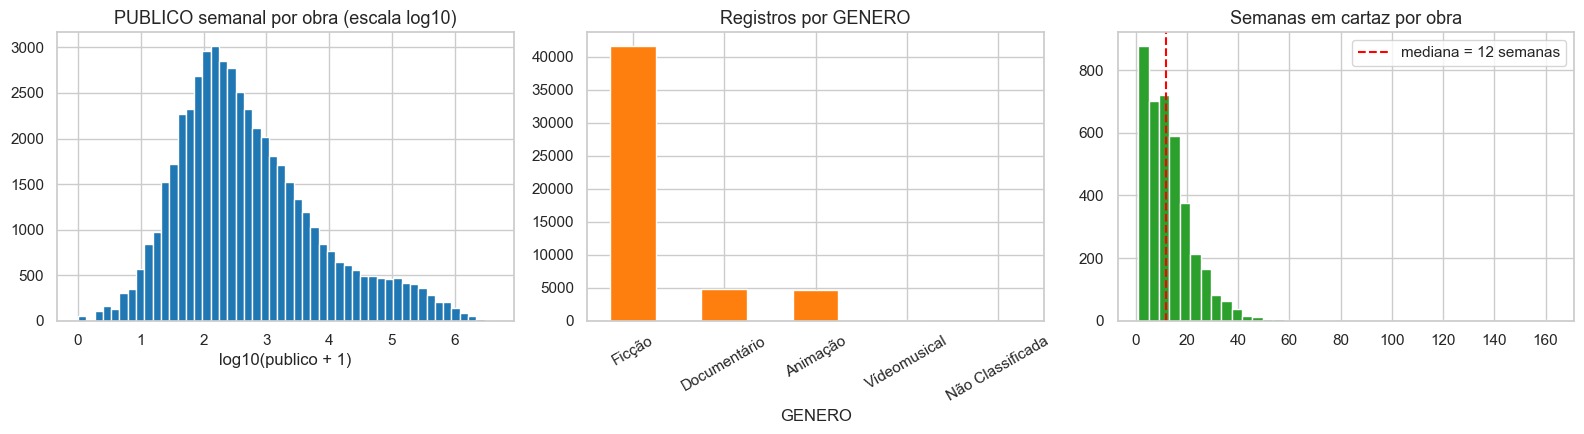

PUBLICO semanal: mediana 323 | media 26,986 | max 4,074,628
Semanas em cartaz: mediana 12 | media 13.2 | max 163


In [8]:
df_obras_aux = df_raw.groupby("CPB_ROE").size().rename("SEMANAS")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].hist(np.log10(df_raw["PUBLICO"] + 1), bins=50, color="#1f77b4")
axes[0].set_title("PUBLICO semanal por obra (escala log10)")
axes[0].set_xlabel("log10(publico + 1)")
df_raw["GENERO"].value_counts().plot.bar(ax=axes[1], color="#ff7f0e")
axes[1].set_title("Registros por GENERO")
axes[1].tick_params(axis="x", rotation=30)
axes[2].hist(df_obras_aux, bins=40, color="#2ca02c")
med = df_obras_aux.median()
axes[2].axvline(med, color="red", ls="--", label=f"mediana = {med:.0f} semanas")
axes[2].set_title("Semanas em cartaz por obra")
axes[2].legend()
plt.tight_layout()
plt.show()

print(f"PUBLICO semanal: mediana {df_raw['PUBLICO'].median():,.0f} | media "
      f"{df_raw['PUBLICO'].mean():,.0f} | max {df_raw['PUBLICO'].max():,.0f}")
print(f"Semanas em cartaz: mediana {med:.0f} | media {df_obras_aux.mean():.1f} | max {df_obras_aux.max()}")

**Achado:** `PUBLICO` permanece assimétrico mesmo em log10 — a massa dos registros está entre 10² e 10⁴ espectadores/semana; `GENERO` é dominado por ficção; a permanência em cartaz concentra-se abaixo de ~30 semanas com cauda até 163.

**Evidência:** mediana de público semanal de 323 ingressos contra média de 26.986 e máximo de 4,07 milhões (razão ~12.600x máx/mediana); mediana de 12 semanas em cartaz.

**Relação com H3/H6 e limite:** a forma das distribuições já sinaliza o padrão "poucos hits, muita cauda" que H3 quantifica, e a vida útil curta de H6. Limite: histogramas de registros semanais e de obras medem coisas diferentes — a mediana de 12 semanas é por **obra**, não ponderada por público.

### Figura 2 — Evolução anual do mercado (H1)

Séries temporais por ano cinematográfico: linhas para os agregados contínuos (público, renda, ticket médio) e barras para o número de obras distintas. O ticket médio é derivado como `RENDA`/`PUBLICO` — razão agregada, não preço de sessão.

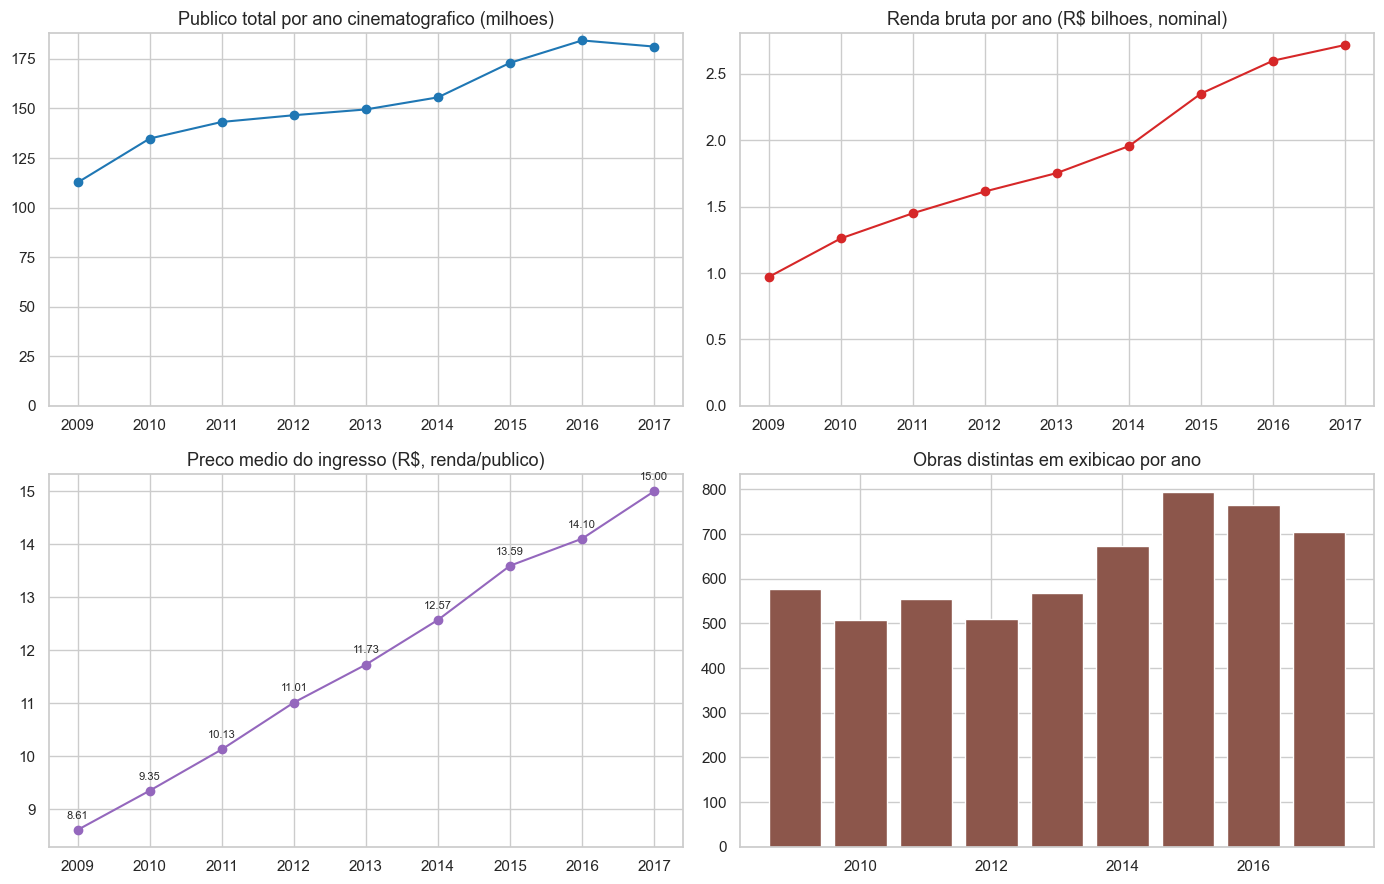

2009 -> 2017: publico +61% | renda nominal +180% | ticket medio +74%


In [9]:
df_raw["ANO"] = pd.to_datetime(df_raw["ANO_CINEMATOGRAFICO"]).dt.year

anual = (df_raw.groupby("ANO")
               .agg(PUBLICO=("PUBLICO", "sum"), RENDA=("RENDA", "sum"),
                    OBRAS=("CPB_ROE", "nunique")))
anual["TICKET_MEDIO"] = anual["RENDA"] / anual["PUBLICO"]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes[0, 0].plot(anual.index, anual["PUBLICO"] / 1e6, marker="o", color="#1f77b4")
axes[0, 0].set_title("Publico total por ano cinematografico (milhoes)")
axes[0, 0].set_ylim(0)
axes[0, 1].plot(anual.index, anual["RENDA"] / 1e9, marker="o", color="#d62728")
axes[0, 1].set_title("Renda bruta por ano (R$ bilhoes, nominal)")
axes[0, 1].set_ylim(0)
axes[1, 0].plot(anual.index, anual["TICKET_MEDIO"], marker="o", color="#9467bd")
axes[1, 0].set_title("Preco medio do ingresso (R$, renda/publico)")
for x, y in zip(anual.index, anual["TICKET_MEDIO"]):
    axes[1, 0].annotate(f"{y:.2f}", (x, y), textcoords="offset points",
                        xytext=(0, 8), ha="center", fontsize=8)
axes[1, 1].bar(anual.index, anual["OBRAS"], color="#8c564b")
axes[1, 1].set_title("Obras distintas em exibicao por ano")
plt.tight_layout()
plt.show()

cresc = lambda c: anual[c].loc[2017] / anual[c].loc[2009] - 1
print(f"2009 -> 2017: publico {cresc('PUBLICO'):+.0%} | renda nominal {cresc('RENDA'):+.0%} | "
      f"ticket medio {cresc('TICKET_MEDIO'):+.0%}")

**Achado:** mercado em expansão até 2016, com leve recuo em 2017; renda cresce muito mais rápido que público.

**Evidência:** público de 112,7 → 181,2 milhões (+61%) com pico de 184,3 mi em 2016; renda nominal de R$ 0,97 → 2,72 bilhões (+180%); ticket médio de R$ 8,61 → R$ 15,00 (+74%); obras de 576 → 705.

**Relação com H1 e limite:** confirma H1 — o crescimento da arrecadação veio principalmente do preço, não de mais frequentadores. Limites: `RENDA` é nominal (parte do crescimento é inflação, não só reajuste real de ingresso); o ticket médio implícito mistura meia-entrada, 3D e salas premium; e o ano cinematográfico não coincide com o civil.

### Figura 3 — Participação do cinema nacional por ano (H2)

Barras agrupadas comparam três shares anuais — obras, público e renda — porque o argumento central é a **divergência** entre presença de catálogo e captação de demanda. A classificação "nacional" segue `PAIS_ORIGEM` contendo "Brasil" (inclui coproduções), conforme decisão **D1**.

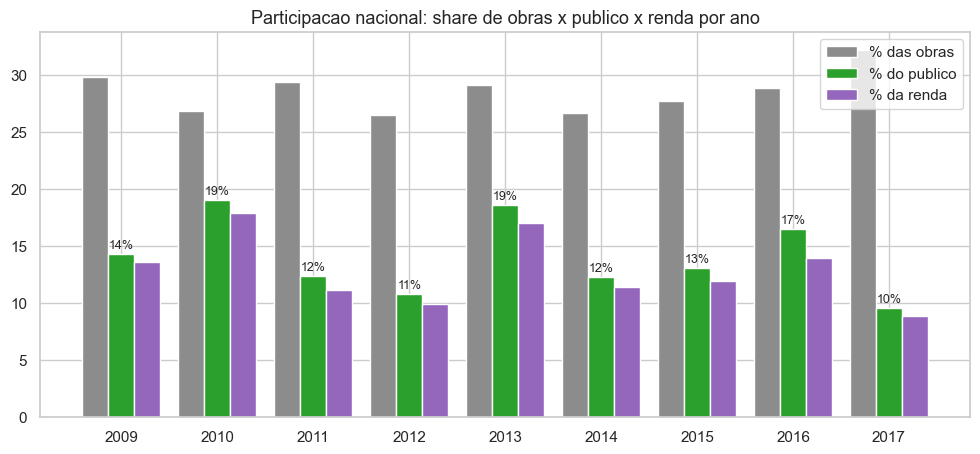

Top 5 obras nacionais (publico acumulado no periodo):
     TITULO_BRASILEIRO  ANO  PUBLICO
    OS DEZ MANDAMENTOS 2016    11.31
      TROPA DE ELITE 2 2010    11.15
MINHA MÃE É UMA PEÇA 2 2016     9.23
    SE EU FOSSE VOCÊ 2 2009     5.79
    DE PERNAS PRO AR 2 2012     4.85


In [10]:
df_raw["NACIONAL"] = (df_raw["PAIS_ORIGEM"].str.split(",")
                      .apply(lambda ps: "Brasil" in [p.strip() for p in ps]))

nat = (df_raw.groupby(["ANO", "NACIONAL"])
             .agg(PUBLICO=("PUBLICO", "sum"), RENDA=("RENDA", "sum"),
                  OBRAS=("CPB_ROE", "nunique")).unstack())
share = pd.DataFrame({"obras": nat["OBRAS"][True] / nat["OBRAS"].sum(axis=1) * 100,
                      "publico": nat["PUBLICO"][True] / nat["PUBLICO"].sum(axis=1) * 100,
                      "renda": nat["RENDA"][True] / nat["RENDA"].sum(axis=1) * 100})

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(share)); w = 0.27
for k, (col, cor, rot) in enumerate([("obras", "#8c8c8c", "% das obras"),
                                     ("publico", COR_NAC, "% do publico"),
                                     ("renda", "#9467bd", "% da renda")]):
    ax.bar(x + (k - 1) * w, share[col], w, label=rot, color=cor)
for i, v in enumerate(share["publico"]):
    ax.annotate(f"{v:.0f}%", (i, v), textcoords="offset points", xytext=(0, 4),
                ha="center", fontsize=9)
ax.set_xticks(x, share.index)
ax.set_title("Participacao nacional: share de obras x publico x renda por ano")
ax.legend()
plt.show()

obras_nat = (df_raw[df_raw["NACIONAL"]]
             .groupby(["CPB_ROE", "TITULO_BRASILEIRO"])
             .agg(ANO=("ANO", "min"), PUBLICO=("PUBLICO", "sum")).reset_index())
print("Top 5 obras nacionais (publico acumulado no periodo):")
print(obras_nat.nlargest(5, "PUBLICO")
      .assign(PUBLICO=lambda t: (t["PUBLICO"] / 1e6).round(2))
      [["TITULO_BRASILEIRO", "ANO", "PUBLICO"]].to_string(index=False))

**Achado:** o share de público nacional oscila ano a ano e fica sistematicamente abaixo do share de obras.

**Evidência:** nacionais = ~29% das obras vs público entre **9,6% (2017) e 19,1% (2010)**; os picos de 2010 e 2016 coincidem com *Tropa de Elite 2* (11,15 mi de espectadores), *Os Dez Mandamentos* (11,31 mi) e *Minha Mãe É uma Peça 2* (9,23 mi) — todos no top-10 geral do período. O ticket médio implícito das nacionais (~R$ 8,50) fica abaixo do das estrangeiras (~R$ 9,90), o que mantém o share de renda levemente abaixo do de público.

**Relação com H2 e limite:** confirma H2 — parcela relevante do catálogo, captação baixa e volátil, dependente de poucos campeões. Limites: um único megassucesso desloca o share anual em vários pontos; e incluir coproduções em "nacional" superestima levemente a fatia de filmes predominantemente brasileiros (quantificado em D1).

### Figura 4 — Concentração: curva de Pareto das obras e top distribuidoras (H3)

A curva de Pareto (público acumulado × % das obras ordenadas) é a visualização direta de concentração; o painel de distribuidoras agrega por `CNPJ_DISTRIBUIDORA`, o identificador estável, exibindo a razão social mais frequente de cada CNPJ.

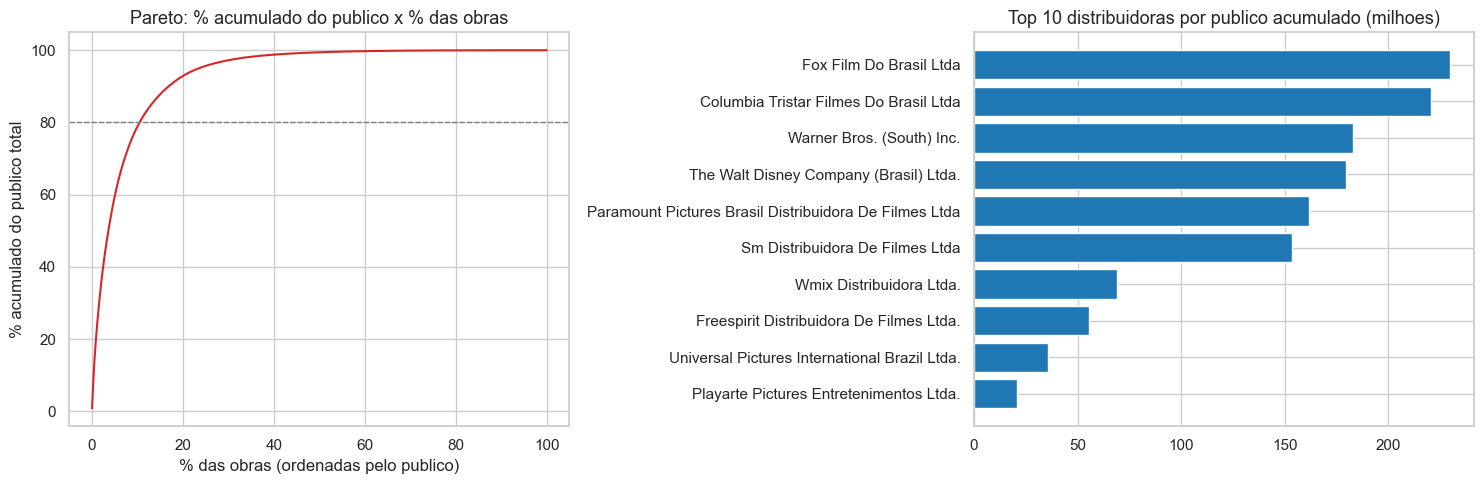

Top 10 obras: 7.3% do publico do periodo
80% do publico concentrado em 405 obras = 10% do catalogo
Top 5 distribuidoras: 70.6% do publico (268 CNPJs no total)
Mediana de publico por distribuidora: 2,510


In [11]:
obras = (df_raw.groupby("CPB_ROE")["PUBLICO"].sum().sort_values(ascending=False))
cum = obras.cumsum() / obras.sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(np.arange(1, len(cum) + 1) / len(cum) * 100, cum.values, color="#d62728")
axes[0].axhline(80, ls="--", color="gray", lw=1)
axes[0].set_title("Pareto: % acumulado do publico x % das obras")
axes[0].set_xlabel("% das obras (ordenadas pelo publico)")
axes[0].set_ylabel("% acumulado do publico total")

dist = (df_raw.groupby("CNPJ_DISTRIBUIDORA")
              .agg(DISTRIBUIDORA=("RAZAO_SOCIAL_DISTRIBUIDORA", "first"),
                   PUBLICO=("PUBLICO", "sum"), OBRAS=("CPB_ROE", "nunique"))
              .sort_values("PUBLICO", ascending=False))
top_dist = dist.head(10).iloc[::-1]
axes[1].barh(top_dist["DISTRIBUIDORA"].str.title(), top_dist["PUBLICO"] / 1e6,
             color="#1f77b4")
axes[1].set_title("Top 10 distribuidoras por publico acumulado (milhoes)")
plt.tight_layout()
plt.show()

n80 = (cum <= 80).sum()
print(f"Top 10 obras: {obras.head(10).sum() / obras.sum():.1%} do publico do periodo")
print(f"80% do publico concentrado em {n80} obras = {n80/len(obras):.0%} do catalogo")
print(f"Top 5 distribuidoras: {dist['PUBLICO'].head(5).sum() / dist['PUBLICO'].sum():.1%} "
      f"do publico ({len(dist)} CNPJs no total)")
print(f"Mediana de publico por distribuidora: {dist['PUBLICO'].median():,.0f}")

**Achado:** concentração mais intensa que a regra 80/20, tanto em obras quanto em distribuidoras.

**Evidência:** 80% de todo o público do período concentra-se em **405 obras (10% do catálogo)**; as 10 maiores somam 7,3%; o top-5 de distribuidoras (Fox, Columbia/Sony, Warner, Disney, Paramount — as majors da época) responde por **70,6%** do público entre 268 CNPJs, enquanto a mediana por CNPJ é de apenas ~2,5 mil espectadores em 9 anos.

**Relação com H3 e limite:** confirma H3. Limites: agregar por CNPJ consolida variações de razão social mas não captura fusões/mudanças societárias ao longo do tempo; e concentração de participação não é medida de poder de mercado — não afirma causalidade.

### Figura 5 — Gêneros e países de origem (H4)

Barras pareadas (share de obras × share de público) evidenciam gêneros que "furam" ou ficam abaixo de sua cota; o ranking de países usa `PAIS_PRINCIPAL` (primeiro da lista) no nível obra.

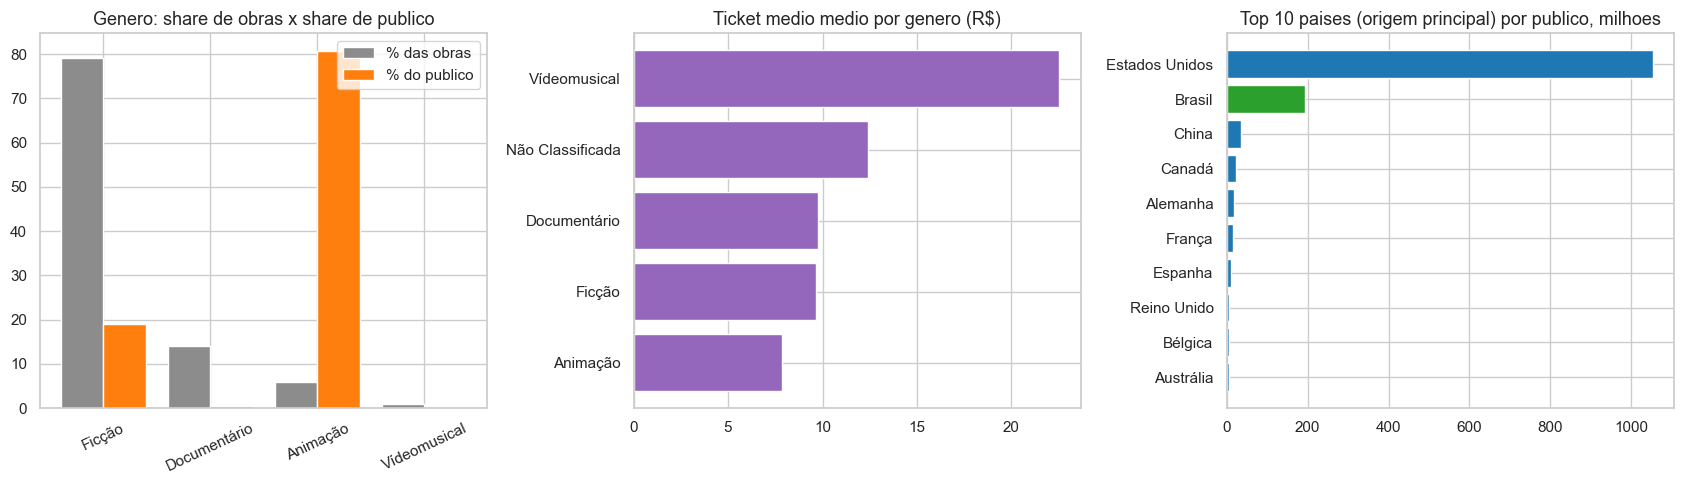

Share de publico por genero: {'Animação': np.float64(18.9), 'Documentário': np.float64(0.4), 'Ficção': np.float64(80.7), 'Vídeomusical': np.float64(0.0)}
Coproducoes: 19% do catalogo


In [12]:
df_raw["PAIS_PRINCIPAL"] = df_raw["PAIS_ORIGEM"].str.split(",").str[0].str.strip()
df_raw["COPRODUCAO"] = df_raw["PAIS_ORIGEM"].str.contains(",")

df_obras_g = (df_raw.groupby("CPB_ROE")
                    .agg(GENERO=("GENERO", "first"), PAIS=("PAIS_PRINCIPAL", "first"),
                         COPROD=("COPRODUCAO", "first"), PUBLICO=("PUBLICO", "sum")))

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
g_obras = df_obras_g["GENERO"].value_counts()
g_pub = df_obras_g.groupby("GENERO")["PUBLICO"].sum() / 1e6
x = np.arange(len(g_obras)); w = 0.4
axes[0].bar(x - w/2, g_obras / g_obras.sum() * 100, w, label="% das obras", color="#8c8c8c")
axes[0].bar(x + w/2, g_pub / g_pub.sum() * 100, w, label="% do publico", color="#ff7f0e")
axes[0].set_xticks(x, g_obras.index, rotation=25)
axes[0].set_title("Genero: share de obras x share de publico")
axes[0].legend()

tkt_g = (df_raw[df_raw["PUBLICO"] > 0]
         .assign(TK=lambda t: t["RENDA"] / t["PUBLICO"])
         .groupby("GENERO")["TK"].mean().sort_values())
axes[1].barh(tkt_g.index, tkt_g.values, color="#9467bd")
axes[1].set_title("Ticket medio medio por genero (R$)")

top_pais = (df_obras_g.groupby("PAIS")["PUBLICO"].sum()
            .sort_values(ascending=False).head(10).iloc[::-1] / 1e6)
axes[2].barh(top_pais.index, top_pais.values,
             color=[COR_NAC if p == "Brasil" else COR_ESTR for p in top_pais.index])
axes[2].set_title("Top 10 paises (origem principal) por publico, milhoes")
plt.tight_layout()
plt.show()

print(f"Share de publico por genero: {dict((g_pub / g_pub.sum() * 100).round(1))}")
print(f"Coproducoes: {df_obras_g['COPROD'].mean():.0%} do catalogo")

**Achado:** ficção domina sem surpresa; os extremos de gênero são os mais informativos — documentário sub-representado em público, animação super-representada.

**Evidência:** documentário = 14% das obras → **0,4%** do público; animação = 6% → **~19%** (coerente com seu ticket médio mais alto); ficção ~79% → ~81%. Países: EUA ~1,05 bilhão de espectadores acumulados, Brasil ~192 mi em 2º; China e Canadá no pelotão por superproduções de animação registradas como coproduções com esses países na 1ª posição; coproduções = 19% do catálogo.

**Relação com H4 e limite:** confirma H4. Limite: `PAIS_PRINCIPAL` = primeiro país da lista atribui o público inteiro de uma coprodução a um só país — o ranking de países não-majoritários é sensível a essa simplificação.

### Figura 6 — Sazonalidade mensal (H5)

Para comparar meses de forma justa, usa-se **público médio por semana exibida** no mês (total do mês ÷ semanas distintas daquele mês), e não o total bruto — meses concentram diferentes números de semanas ao longo de 9 anos.

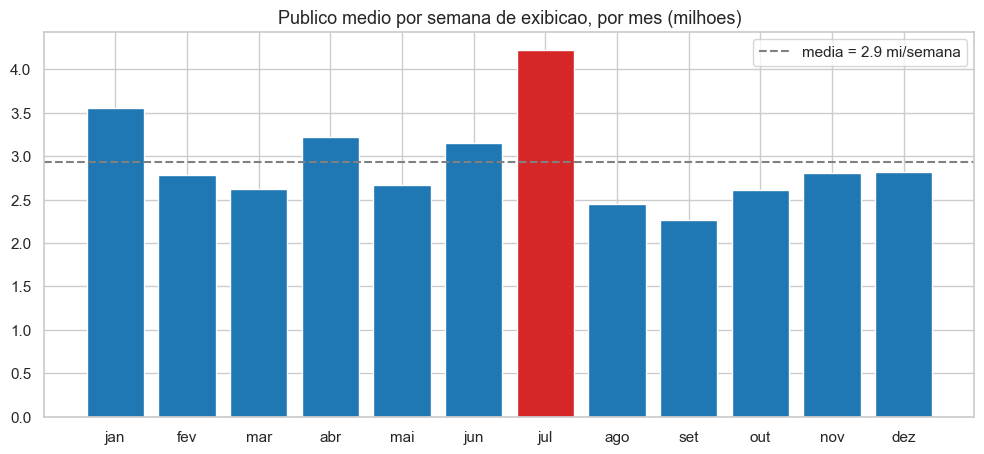

Melhor mes: jul (4.22 mi/sem) | pior: set (2.27 mi/sem) | razao 1.9x


In [13]:
df_raw["MES"] = pd.to_datetime(df_raw["DT_INICIO_EXIBICAO"]).dt.month
pub_sem = (df_raw.groupby("MES")["PUBLICO"].sum() /
           df_raw.groupby("MES")["DT_INICIO_EXIBICAO"].nunique())

nomes = ["jan","fev","mar","abr","mai","jun","jul","ago","set","out","nov","dez"]
fig, ax = plt.subplots(figsize=(12, 5))
cores = ["#d62728" if v == pub_sem.max() else "#1f77b4" for v in pub_sem.values]
ax.bar([nomes[m - 1] for m in pub_sem.index], pub_sem.values / 1e6, color=cores)
ax.axhline(pub_sem.mean() / 1e6, ls="--", color="gray",
           label=f"media = {pub_sem.mean()/1e6:.1f} mi/semana")
ax.set_title("Publico medio por semana de exibicao, por mes (milhoes)")
ax.legend()
plt.show()

print(f"Melhor mes: {nomes[pub_sem.idxmax()-1]} ({pub_sem.max()/1e6:.2f} mi/sem) | "
      f"pior: {nomes[pub_sem.idxmin()-1]} ({pub_sem.min()/1e6:.2f} mi/sem) | "
      f"razao {pub_sem.max()/pub_sem.min():.1f}x")

**Achado:** sazonalidade clara e coerente com o calendário escolar.

**Evidência:** julho é o melhor mês (4,22 mi/semana, 40% acima da média de 3,0), seguido de janeiro (3,56), abril (3,22) e junho (3,15); os vales são setembro (2,27), agosto (2,45) e outubro (2,61) — amplitude de 1,9x entre melhor e pior mês.

**Relação com H5 e limite:** confirma H5. Limites: o mês de início da semana de exibição aproxima o mês efetivo da bilheteria; a série mistura 9 anos sem decompor tendência × sazonalidade × efeito de lançamentos pontuais (um megassucesso concentrado num mês pode inflá-lo em anos isolados).

### Figura 7 — Permanência em cartaz e salas × público (H6)

O histograma compara a distribuição de semanas em cartaz por origem; o scatter log-log relaciona `SALAS` e `PUBLICO` semanais — escala logarítmica obrigatória pela amplitude. O recorte exclui registros com `PUBLICO = 0`, fora do eixo log.

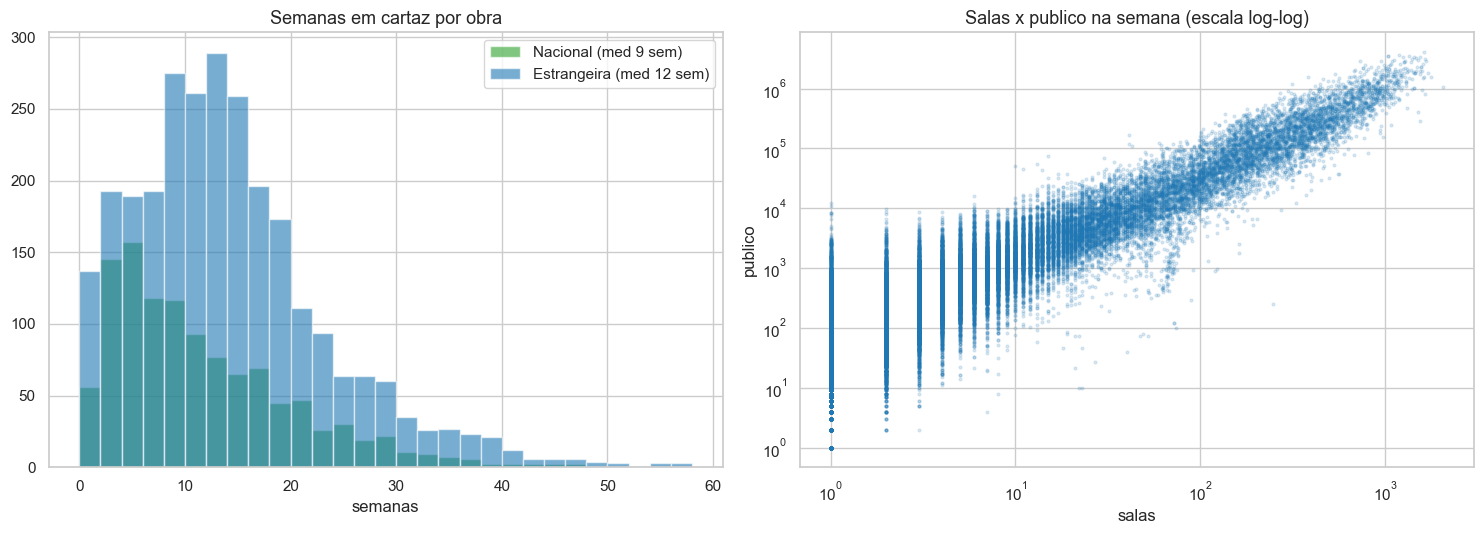

Publico semanal mediano POR SALA, por faixa de capilaridade:
faixa
1-10          83.0
11-50        181.0
51-200       305.0
201-500      530.0
501-1000     792.0
1000+       1229.0

Obras fora de cartaz em ate 4 semanas: 18%
Obras em cartaz por mais de 26 semanas: 9%


In [14]:
df_obras_sem = (df_raw.groupby(["CPB_ROE", "NACIONAL"])
                      .agg(SEMANAS=("DT_INICIO_EXIBICAO", "nunique")).reset_index())

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for origem, cor, nac in [("Nacional", COR_NAC, True), ("Estrangeira", COR_ESTR, False)]:
    s = df_obras_sem.loc[df_obras_sem["NACIONAL"] == nac, "SEMANAS"]
    axes[0].hist(s, bins=np.arange(0, 60, 2), alpha=0.6,
                 label=f"{origem} (med {s.median():.0f} sem)", color=cor)
axes[0].set_title("Semanas em cartaz por obra")
axes[0].set_xlabel("semanas"); axes[0].legend()

mov = df_raw[df_raw["PUBLICO"] > 0]
axes[1].scatter(mov["SALAS"], mov["PUBLICO"], s=4, alpha=0.15, color="#1f77b4")
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_title("Salas x publico na semana (escala log-log)")
axes[1].set_xlabel("salas"); axes[1].set_ylabel("publico")
plt.tight_layout()
plt.show()

faixas = pd.cut(mov["SALAS"], [0, 10, 50, 200, 500, 1000, 2100],
                labels=["1-10", "11-50", "51-200", "201-500", "501-1000", "1000+"])
pps = mov.assign(faixa=faixas).groupby("faixa", observed=True).apply(
    lambda g: (g["PUBLICO"] / g["SALAS"]).median(), include_groups=False)
print("Publico semanal mediano POR SALA, por faixa de capilaridade:")
print(pps.round(0).to_string())
print(f"\nObras fora de cartaz em ate 4 semanas: {(df_obras_sem['SEMANAS'] <= 4).mean():.0%}")
print(f"Obras em cartaz por mais de 26 semanas: {(df_obras_sem['SEMANAS'] > 26).mean():.0%}")

**Achado:** vida útil curta para a maioria das obras — e rendimento por sala que **cresce** com a capilaridade.

**Evidência:** 18% das obras saem de cartaz em ≤4 semanas e só 9% passam de 26; mediana de 9 semanas (nacional) vs 12 (estrangeira). Público semanal mediano por sala: ~83 (1–10 salas) → ~1.229 (1.000+ salas) — subindo, não caindo, com a escala.

**Relação com H6 e limite:** H6 é **parcialmente refutada** — vida útil curta se confirma, mas a saturação não se verifica: lançamentos amplos rendem mais por sala, coerente com distribuidoras alocando capilaridade onde a demanda esperada é maior. Limite: associação, não causalidade — mais salas não "causam" mais público; e a mediana por faixa não isola a semana de estreia, onde o efeito é mais forte.

# 5. Pré-processamento e decisões

## 5.1 Plano e prevenção de vazamento

**Diagnóstico que orienta a preparação** (seção 4): nenhuma ausência a imputar; tipos de data a corrigir; `PAIS_ORIGEM` a normalizar; `COPIAS` não confiável; e a unidade de análise alternando entre registro semanal e obra, o que exige uma segunda visão agregada.

**Visões preservadas:** `df_raw` permanece intocado (visão original). Produzem-se: `df` (obra × semana, tipos corrigidos e variáveis derivadas) e `df_obras` (uma linha por obra, chave `CPB_ROE`).

**Prevenção de vazamento — não aplicável neste escopo:** o trabalho é uma análise descritiva da população observada; não há ajuste de parâmetros, treinamento de modelo nem seleção de variáveis aprendida dos dados — logo, não existe risco de vazamento nem necessidade de divisão treino/teste. Caso a etapa preditiva futura (regressão sobre `PUBLICO` de estreia) se concretize, o split deverá ocorrer **antes** de qualquer aprendizado de parâmetros — e, pela natureza temporal do problema, recomenda-se split temporal (anos anteriores → treino; último ano → teste), não aleatório.

In [15]:
# df: nivel obra x semana — tipos corrigidos + variaveis derivadas
df = df_raw.copy()
df["DT_INICIO"] = pd.to_datetime(df["DT_INICIO_EXIBICAO"])
df["DT_FIM"] = pd.to_datetime(df["DT_FIM_EXIBICAO"])
df["ANO"] = pd.to_datetime(df["ANO_CINEMATOGRAFICO"]).dt.year
df["MES"] = df["DT_INICIO"].dt.month
df["PAIS_PRINCIPAL"] = df["PAIS_ORIGEM"].str.split(",").str[0].str.strip()
df["N_PAISES"] = df["PAIS_ORIGEM"].str.split(",").str.len()
df["COPRODUCAO"] = df["N_PAISES"] > 1
df["NACIONAL"] = df["PAIS_ORIGEM"].str.split(",").apply(
    lambda ps: "Brasil" in [p.strip() for p in ps])
df["ORIGEM"] = np.where(df["NACIONAL"], "Nacional", "Estrangeira")
df["TICKET_MEDIO"] = np.where(df["PUBLICO"] > 0, df["RENDA"] / df["PUBLICO"], np.nan)

# df_obras: nivel obra (uma linha por filme; chave CPB_ROE)
df_obras = (df.groupby("CPB_ROE")
              .agg(TITULO=("TITULO_BRASILEIRO", "first"), GENERO=("GENERO", "first"),
                   PAIS_PRINCIPAL=("PAIS_PRINCIPAL", "first"), NACIONAL=("NACIONAL", "first"),
                   ANO=("ANO", "min"), CNPJ_DISTRIBUIDORA=("CNPJ_DISTRIBUIDORA", "first"),
                   DISTRIBUIDORA=("RAZAO_SOCIAL_DISTRIBUIDORA", "first"),
                   SEMANAS_CARTAZ=("DT_INICIO", "nunique"), SALAS_MAX=("SALAS", "max"),
                   PUBLICO=("PUBLICO", "sum"), RENDA=("RENDA", "sum")).reset_index())
df_obras["TICKET_MEDIO"] = df_obras["RENDA"] / df_obras["PUBLICO"]
df_obras["ORIGEM"] = np.where(df_obras["NACIONAL"], "Nacional", "Estrangeira")
df_obras.head()

,CPB_ROE,TITULO,GENERO,PAIS_PRINCIPAL,NACIONAL,ANO,CNPJ_DISTRIBUIDORA,DISTRIBUIDORA,SEMANAS_CARTAZ,SALAS_MAX,PUBLICO,RENDA,TICKET_MEDIO,ORIGEM
0,B0300007100000,VIVA VOZ,Ficção,Brasil,True,2009,00.979.601/0001-98,COLUMBIA TRISTAR FILMES DO BRASIL LTDA,1,1,429,1287.0,3.000000,Nacional
1,B0300008800000,MADAME SATÃ,Ficção,Brasil,True,2014,31.179.864/0001-46,VIDEOFILMES PRODUÇÕES ARTÍSTICA LTDA,2,1,32,164.0,5.125000,Nacional
2,B0300040300000,DE PASSAGEM,Ficção,Brasil,True,2010,08.331.280/0001-22,RAIZ DISTRIBUIDORA AUDIOVISUAL LTDA.,2,1,3701,11248.0,3.039179,Nacional
3,B0400051700000,"AMIGO INVISÍVEL, O",Ficção,Brasil,True,2011,08.331.280/0001-22,RAIZ DISTRIBUIDORA AUDIOVISUAL LTDA.,11,3,40588,121672.0,2.997733,Nacional
4,B0400076000000,PAULINHO DA VIOLA - MEU TEMPO É HOJE,Documentário,Brasil,True,2013,31.179.864/0001-46,VIDEOFILMES PRODUÇÕES ARTÍSTICA LTDA,1,1,3,24.0,8.000000,Nacional


## 5.2 D1 — Classificação de obra "nacional"

**Necessidade e evidência:** a classificação cadastral (prefixo `B`/`E` do `CPB_ROE`) diverge do `PAIS_ORIGEM` declarado em 142 registros (prefixo `E` com "Brasil" entre os países) — ver tabulação cruzada na seção 4.1.

**Alternativas:** (a) classificar pelo prefixo do registro; (b) `PAIS_ORIGEM` contém "Brasil" — inclui coproduções com participação brasileira; (c) apenas obras exclusivamente brasileiras.

**Escolha e justificativa:** **(b)**. `PAIS_ORIGEM` é o atributo descritivo do fenômeno medido e captura a coprodução como forma de produção nacional; o prefixo reflete a formalidade do registro, não necessariamente a origem efetiva.

In [16]:
# D1 - comparacao efetiva das tres regras de classificacao
regra_prefixo = df["CPB_ROE"].str[0] == "B"
regra_pais = df["NACIONAL"]
regra_estrita = df["PAIS_ORIGEM"].str.strip() == "Brasil"

comp = pd.DataFrame({
    "regra": ["(a) prefixo CPB=B", "(b) contem Brasil", "(c) exclusivamente Brasil"],
    "registros": [regra_prefixo.sum(), regra_pais.sum(), regra_estrita.sum()],
    "share_publico_%": [df.loc[regra_prefixo, "PUBLICO"].sum() / df["PUBLICO"].sum() * 100,
                        df.loc[regra_pais, "PUBLICO"].sum() / df["PUBLICO"].sum() * 100,
                        df.loc[regra_estrita, "PUBLICO"].sum() / df["PUBLICO"].sum() * 100]})
comp["share_publico_%"] = comp["share_publico_%"].round(2)
print(comp.to_string(index=False))
print(f"\nRegistros divergentes entre (a) e (b): {(regra_prefixo != regra_pais).sum()} "
      f"({(regra_prefixo != regra_pais).mean():.2%})")

                    regra  registros  share_publico_%
        (a) prefixo CPB=B      12813            13.92
        (b) contem Brasil      12955            13.95
(c) exclusivamente Brasil      11331            13.66

Registros divergentes entre (a) e (b): 142 (0.28%)


**Resultado e validação:** as três regras produzem shares de público nacional de 13,9%, 14,0% e 13,7% — a escolha não altera nenhuma conclusão material, o que valida usar a mais informativa conceitualmente (b). A divergência (a)×(b) afeta apenas 142 registros (0,28%).

**Limitação:** incluir coproduções superestima levemente a fatia de filmes predominantemente brasileiros; a regra (c) faria o oposto, ignorando a coprodução como produção nacional legítima.

## 5.3 D2 — Medida de capilaridade: `SALAS` em vez de `COPIAS`

**Necessidade e evidência:** `COPIAS = 0` em 38% dos registros com `SALAS ≥ 1`, e `SALAS > COPIAS` em ~50% — impossível se `COPIAS` medisse cópias em circulação na semana (seção 4.1).

**Alternativas:** (a) usar `COPIAS`; (b) usar `SALAS`; (c) usar ambas.

**Escolha e justificativa:** **(b)**. `SALAS` mede diretamente a capilaridade semanal da exibição; `COPIAS` parece registrar o volume de lançamento e não é atualizado semana a semana. O campo é mantido nos dados, mas fora das análises de capilaridade.

In [17]:
# D2 - comparacao e verificacao
print(f"SALAS:  min={df['SALAS'].min()}, zeros={(df['SALAS'] == 0).sum()}, mediana={df['SALAS'].median():.0f}")
print(f"COPIAS: min={df['COPIAS'].min()}, zeros={(df['COPIAS'] == 0).sum()} "
      f"({(df['COPIAS'] == 0).mean():.0%}), mediana={df['COPIAS'].median():.0f}")
print(f"Correlacao com PUBLICO (spearman): SALAS "
      f"{df[['SALAS', 'PUBLICO']].corr(method='spearman').iloc[0, 1]:.2f} | COPIAS "
      f"{df[['COPIAS', 'PUBLICO']].corr(method='spearman').iloc[0, 1]:.2f}")

SALAS:  min=1, zeros=0, mediana=3
COPIAS: min=0, zeros=19473 (38%), mediana=1
Correlacao com PUBLICO (spearman): SALAS 0.88 | COPIAS 0.44


**Resultado e validação:** `SALAS` não tem zeros espúrios (mínimo 1) e correlaciona-se com `PUBLICO` em 0,88 (Spearman), coerente com capilaridade efetiva; `COPIAS` zeraria artificialmente 38% das observações e correlação cai a 0,44 — confirma-se que `COPIAS` não mede a mesma coisa no recorte semanal.

**Limitação:** sem documentação oficial do campo `COPIAS`, sua interpretação permanece incerta; a decisão conservadora é não inferir nada a partir dele.

## 5.4 D3 — Registros com `PUBLICO = 0` e `RENDA = 0`: manter

**Necessidade e evidência:** 54 registros (0,1%) de obras em cartaz sem público nem renda reportados na semana (seção 4.1).

**Alternativas:** (a) remover como suspeita de erro; (b) manter; (c) imputar.

**Escolha e justificativa:** **(b) manter.** São plausíveis — obra residual em cartaz sem movimento ou reporte incompleto da exibidora —, não violam nenhuma regra de consistência e somam zero nos agregados; remover seria deletar informação sem evidência de erro.

In [18]:
# D3 - verificacao do efeito agregado de remover vs manter
com_zeros = df["PUBLICO"].sum()
sem_zeros = df.loc[df["PUBLICO"] > 0, "PUBLICO"].sum()
print(f"PUBLICO total mantendo zeros: {com_zeros:,}")
print(f"PUBLICO total removendo zeros: {sem_zeros:,} (diferenca: {com_zeros - sem_zeros})")
print(f"TICKET_MEDIO NaN (indefinido onde PUBLICO=0): {df['TICKET_MEDIO'].isna().sum()}")

PUBLICO total mantendo zeros: 1,381,024,924
PUBLICO total removendo zeros: 1,381,024,924 (diferenca: 0)
TICKET_MEDIO NaN (indefinido onde PUBLICO=0): 54


**Resultado e validação:** manter ou remover não altera nenhum total (diferença = 0); a única consequência é `TICKET_MEDIO` indefinido nesses 54 registros — tratado explicitamente com `NaN` estrutural, não imputado.

**Limitação:** se os zeros forem falhas de reporte, subestimam levemente público/renda das obras afetadas — impacto desprezível em 0,1% dos registros.

**Decisão complementar (chave de agregação):** agrega-se por `CPB_ROE`, não por título — 10 títulos brasileiros são compartilhados por obras distintas (*Lola*, *O Mensageiro*, *A Despedida*…) e 1 CPB tem dois títulos; distribuidoras agregam por `CNPJ_DISTRIBUIDORA` (268) e não por razão social (274 variações).

## 5.5 Estado final dos dados

Transformações **não** aplicadas, com justificativa: remoção de outliers (extremos são o fenômeno — ver H3); imputação (não há ausências; `NaN` de `TICKET_MEDIO` é estrutural); balanceamento, codificação one-hot e escalonamento (sem modelos neste escopo, manter categorias e escalas originais preserva a interpretabilidade); PCA/discretização (dimensionalidade pequena e legível).

In [19]:
# Verificacoes finais de integridade: antes x depois
print("Integridade das versoes:")
print(f"  df_raw: {df_raw.shape[0]:,} x {df_raw.shape[1]} | df: {df.shape[0]:,} x {df.shape[1]}")
print(f"  Linhas preservadas: {len(df) == len(df_raw)} | "
      f"CPBs preservados: {df['CPB_ROE'].nunique() == df_raw['CPB_ROE'].nunique()}")
print(f"  PUBLICO: raw {df_raw['PUBLICO'].sum():,} = df {df['PUBLICO'].sum():,} = "
      f"obras {df_obras['PUBLICO'].sum():,}")
print(f"  RENDA:   raw {df_raw['RENDA'].sum():,.0f} = df {df['RENDA'].sum():,.0f} = "
      f"obras {df_obras['RENDA'].sum():,.0f}")
print(f"  Ausencias novas: {df.isna().sum().sum() - df_raw.isna().sum().sum():.0f} "
      f"(esperado: {df['PUBLICO'].eq(0).sum()}, de TICKET_MEDIO onde PUBLICO=0)")
print(f"  df_obras: {len(df_obras)} linhas = {df['CPB_ROE'].nunique()} obras unicas")

# Exporta a visao por obra (unico artefato derivado necessario a uma etapa futura).
# mkdir garante a pasta no Colab, onde o repositorio nao e clonado.
from pathlib import Path
Path("data").mkdir(exist_ok=True)
df_obras.to_csv("data/bilheteria_por_obra_2009_2017.csv", index=False)
print("\nExportado: data/bilheteria_por_obra_2009_2017.csv (visao por obra)")

Integridade das versoes:
  df_raw: 51,176 x 20 | df: 51,176 x 25
  Linhas preservadas: True | CPBs preservados: True
  PUBLICO: raw 1,381,024,924 = df 1,381,024,924 = obras 1,381,024,924
  RENDA:   raw 16,671,989,431 = df 16,671,989,431 = obras 16,671,989,431
  Ausencias novas: 54 (esperado: 54, de TICKET_MEDIO onde PUBLICO=0)
  df_obras: 3876 linhas = 3876 obras unicas

Exportado: data/bilheteria_por_obra_2009_2017.csv (visao por obra)


# 6. Respostas e conclusão

| Pergunta | Resposta apoiada pelos dados | Evidência e localização | Limitação |
|---|---|---|---|
| H1 | **Confirmada** — renda cresceu muito mais que público, puxada pelo preço | Público +61% (112,7→181,2 mi) vs renda +180% (R$0,97→2,72 bi); ticket R$8,61→15,00 — Figura 2 | Renda nominal (inclui inflação); ticket implícito ≠ preço de sessão |
| H2 | **Confirmada** — ~29% das obras, share de público baixo e instável | Share 9,6–19,1%/ano; picos = Tropa de Elite 2, Os Dez Mandamentos, Minha Mãe É uma Peça 2 — Figura 3 | Coproduções inflam levemente "nacional" (D1); share sensível a poucos hits |
| H3 | **Confirmada** — concentração extrema | 10% do catálogo = 80% do público; top-5 distribuidoras = 70,6% — Figura 4 | Concentração ≠ poder de mercado; CNPJ não captura fusões |
| H4 | **Confirmada** — ficção/EUA dominam; documentário sem público | Doc: 14% obras → 0,4% público; animação 6% → ~19%; EUA ~1,05 bi vs Brasil ~192 mi — Figura 5 | Público de coproduções atribuído ao país principal |
| H5 | **Confirmada** — sazonalidade de férias escolares | Jul 4,22 mi/sem vs set 2,27 (1,9x); jan 2º — Figura 6 | Sem decomposição tendência × sazonalidade; efeito de hits pontuais |
| H6 | **Parcialmente refutada** — vida útil curta sim; saturação por sala não | Mediana 12 sem (nac 9); público/sala mediano sobe de ~83 a ~1.229 por faixa — Figura 7 | Associação, não causalidade; mediana não isola semana de estreia |

**Síntese:** entre 2009 e 2017, a bilheteria brasileira cresceu — mas cresceu **pelo preço**, não pelo hábito. Estruturalmente, é um mercado de extrema concentração — em obras, distribuidoras e origem — em que o cinema nacional existe com volume relevante de produção (1 em cada 3 filmes em cartaz) mas capta uma fatia pequena e instável da arrecadação, sustentada por raros fenômenos de público.

**Perguntas em aberto e próximos passos:** decomposição da renda em termos reais (deflação por IPCA); cruzamento com o cadastro de salas/complexos por UF para análise regional oferta × demanda; análise da semana de estreia (capilaridade inicial × público de abertura); e, na etapa preditiva, regressão de público com split temporal anterior a qualquer aprendizado de parâmetros.

## Referências

- ANCINE — Dados Abertos: *Bilheteria de Obras por Semana* — https://dados.gov.br · https://oca.ancine.gov.br (obtido em novembro de 2026)
- ANCINE/OCA — Anuário Estatístico do Cinema Brasileiro (contexto do mercado)
- Documentação: pandas (pandas.pydata.org), matplotlib (matplotlib.org), seaborn (seaborn.pydata.org)

## Declaração de uso de Inteligência Artificial

Declaro que ferramentas de IA foram utilizadas neste trabalho como **apoio operacional e técnico** — programação, geração de gráficos, tratamento de dados e depuração de código — nos termos permitidos pela disciplina. A definição do problema, o desenho das perguntas, a análise exploratória, a interpretação dos resultados e as conclusões são de minha responsabilidade e refletem meu exame crítico dos dados.

*Ferramenta utilizada: Devin (Cognition AI).*

# 7. Checklist de entrega

| Item | Localização no notebook | Não aplicabilidade, se houver |
|---|---|---|
| 1. Problema, unidade, perguntas e objetivo | Seções 1.1 e 1.2 | — |
| 2. Fonte, período, recortes e dicionário | Seções 2.1 e 2.2 | — |
| 3. Dimensões, tipos e estatísticas | Seções 4.1 e 4.2 | Medidas sem sentido para identificadores justificadas em 4.2 |
| 4. Ausências, duplicidades, inconsistências e extremos | Seção 4.1 | Extremos × erros diferenciados em 4.1 |
| 5. Distribuições, relações e classes, quando aplicável | Seções 4.2 e 4.3 (Figuras 1–7) | Sem alvo de classificação — análise descritiva (seção 1.1) |
| 6. Interpretações das figuras | Markdown após cada Figura 1–7 | Formato Achado/Evidência/Relação e limite |
| 7. D1–D3 e comparação de alternativas | Seções 5.2–5.4 | Comparação efetiva executada em D1 (três regras) e D2 |
| 8. Transformações ou manutenção e verificações | Seções 5.1 e 5.5 | Não-aplicadas justificadas em 5.5 |
| 9. Prevenção de vazamento ou não aplicabilidade | Seção 5.1 | Não aplicável: análise descritiva, sem aprendizado de parâmetros |
| 10. Conclusão, limites e próximos passos | Seção 6 | — |
| 11. Referências e declaração de IA | Seção 6 (Referências; Declaração de uso de IA) | — |
| 12. Finalização, execução, dados e link do Colab | Capa; seção 3; `data/` e `requirements.txt` no repositório | Dataset lido via URL raw do GitHub |